In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eigh

In [2]:
#parameters
hbar =1.0
a = 0.5   # lattice constant
t=1.0   # hopping parameter
epsilon =0.0  #On-site energy
N_k = 500

# building bloch hamiltonian
# k-grid covering the First Brillouin Zone: [-π/a, π/a]
k_grid = np.linspace(-np.pi / a, np.pi / a, N_k)

#theoritical effective mass
m_theor = (hbar**2)/(2*t*a**2)

#building bloch hamiltonian
E_k = -2 * t * np.cos(k_grid * a)
#print(E_k)
'''E_k2 = np.zeros(N_k)
for i,k in enumerate(k_grid):
    H_k = np.array([[epsilon - 2*t*np.cos(k*a)]])
    evals,_ = np.linalg.eigh(H_k)
    E_k2[i]= evals[0]

print(E_k2) '''

'E_k2 = np.zeros(N_k)\nfor i,k in enumerate(k_grid):\n    H_k = np.array([[epsilon - 2*t*np.cos(k*a)]])\n    evals,_ = np.linalg.eigh(H_k)\n    E_k2[i]= evals[0]\n\nprint(E_k2) '

In [3]:
#curve fit
k_cutoff = 0.10 * (np.pi/a)

mask = np.abs(k_grid) <= k_cutoff
k_fit= k_grid[mask]
E_fit= E_k[mask]

# c2 corresponds to (1/2) * d²E/dk²
coefficients = np.polyfit(k_fit, E_fit, 2)
c2, c1, c0 = coefficients

m_num = (hbar**2) / (2*c2) 



In [4]:
# Output numerical comparison
print(f"--- Effective Mass Extraction Results ---")
print(f"Polynomial fit coefficient c2 (d²E/dk² / 2) : {c2:.6f}")
#print(f"Numerical d²E/dk² at k=0                   : {d2E_dk2_numerical:.6f}")
#print(f"Theoretical d²E/dk² (2*t*a²)               : {2*t*(a**2):.6f}")
print(f"Numerical m*                               : {m_num:.6f}")
print(f"Theoretical m*                             : {m_theor:.6f}")
print(
    f"Relative Error                             :"
    f" {abs(m_num - m_theor)/m_theor * 100:.4f}%"
)

--- Effective Mass Extraction Results ---
Polynomial fit coefficient c2 (d²E/dk² / 2) : 0.248238
Numerical m*                               : 2.014193
Theoretical m*                             : 2.000000
Relative Error                             : 0.7096%


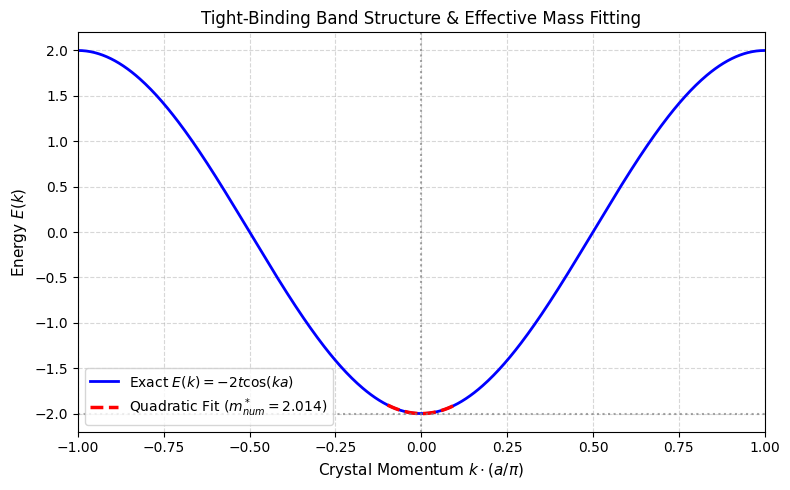

In [5]:
plt.figure(figsize=(8, 5))

# Plot full band structure
plt.plot(
    k_grid * a / np.pi, E_k, 'b-', linewidth=2, label=r'Exact $E(k) = -2t\cos(ka)$'
)

# Plot quadratic fit overlay near k=0
E_fitted_curve = c2 * (k_fit**2) + c1 * k_fit + c0
plt.plot(
    k_fit * a / np.pi,
    E_fitted_curve,
    'r--',
    linewidth=2.5,
    label=rf'Quadratic Fit ($m_{{num}}^* = {m_num:.3f}$)',
)

# Formatting
plt.axvline(0, color='gray', linestyle=':', alpha=0.7)
plt.axhline(epsilon - 2 * t, color='gray', linestyle=':', alpha=0.7)
plt.title('Tight-Binding Band Structure & Effective Mass Fitting', fontsize=12)
plt.xlabel(r'Crystal Momentum $k \cdot (a / \pi)$', fontsize=11)
plt.ylabel('Energy $E(k)$', fontsize=11)
plt.xlim(-1, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

<>:60: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
<>:60: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_30144\1213207680.py:60: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  plt.xlabel('Wavevector $k$ ($1/\AA$)', fontsize=11)


Input Mass (m*)        : 1.0000
Finite-Difference Fitted m* : 1.0008


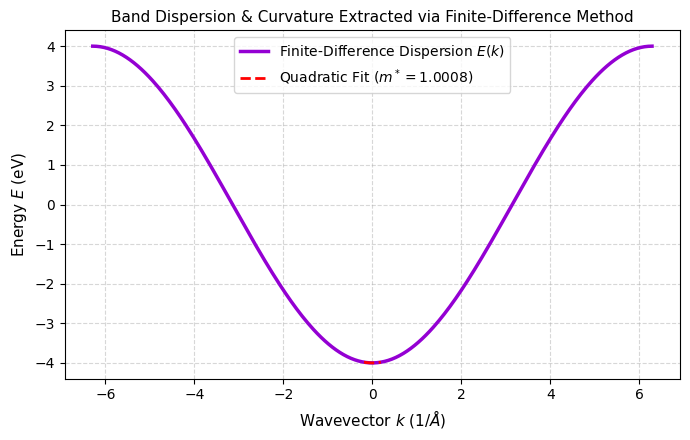

In [15]:
# Finite difference method

# Parameters
N = 100  # Number of real-space grid points
a = 0.5  # Grid spacing (Å)
hbar = 1.0  # Reduced Planck constant
m_input = 1.0  # Target mass we will simulate

# Pre-factor for finite difference kinetic energy: t_eff = ħ^2 / (2 * m * a^2)
t_eff = (hbar**2) / (2 * m_input * a**2)

# Constructing the real-space tridiagonal Hamiltonian matrix (Periodic Boundary Conditions)
H = np.zeros((N, N))
for i in range(N):
  H[i, i] = 2 * t_eff
  H[i, (i + 1) % N] = -t_eff
  H[i, (i - 1 + N) % N] = -t_eff

# To find E(k), we can apply Bloch phase shifts or diagonalize across k-space
# Alternatively, we can extract m* directly from the lowest eigenvectors / finite difference curvature.
# Let's compute E(k) by evaluating the expectation value of the FD Hamiltonian with Bloch waves:
k_grid = np.linspace(-np.pi / a, np.pi / a, 300)
E_fd = np.zeros_like(k_grid)

for idx, k in enumerate(k_grid):
  # Construct Bloch-periodic Hamiltonian for a single unit cell / phase
  # H_k = 2*t_eff - t_eff*exp(i*k*a) - t_eff*exp(-i*k*a) = 2*t_eff*(1 - cos(k*a))
  E_fd[idx] = 2 * t_eff * (1- np.cos(k * a))
  # Shift to match band bottom at -2*t_eff
  E_fd[idx] -= 2 * t_eff

# Fit curvature near k = 0 to recover m*
k_mask = np.abs(k_grid) < 0.2
k_fit = k_grid[k_mask]
E_fit = E_fd[k_mask]

coeffs = np.polyfit(k_fit**2, E_fit, 1)  # E(k) = c2 * k^2 + c0
c2 = coeffs[0]
m_extracted = (hbar**2) / (2 * c2)

print(f'Input Mass (m*)        : {m_input:.4f}')
print(f'Finite-Difference Fitted m* : {m_extracted:.4f}')

# Plotting the Finite Difference Dispersion
plt.figure(figsize=(7, 4.5))
plt.plot(
    k_grid,
    E_fd,
    color='darkviolet',
    lw=2.5,
    label='Finite-Difference Dispersion $E(k)$',
)
plt.plot(
    k_fit,
    coeffs[1] + coeffs[0] * k_fit**2,
    'r--',
    lw=2,
    label=f'Quadratic Fit ($m^* = {m_extracted:.4f}$)',
)
plt.xlabel('Wavevector $k$ ($1/\AA$)', fontsize=11)
plt.ylabel('Energy $E$ (eV)', fontsize=11)
plt.title(
    'Band Dispersion & Curvature Extracted via Finite-Difference Method',
    fontsize=11,
)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

--- FIRST 10 ENERGY LEVELS ---
E_1 = 0.0003 eV
E_2 = 0.0012 eV
E_3 = 0.0027 eV
E_4 = 0.0048 eV
E_5 = 0.0075 eV
E_6 = 0.0108 eV
E_7 = 0.0147 eV
E_8 = 0.0192 eV
E_9 = 0.0243 eV
E_10 = 0.0300 eV


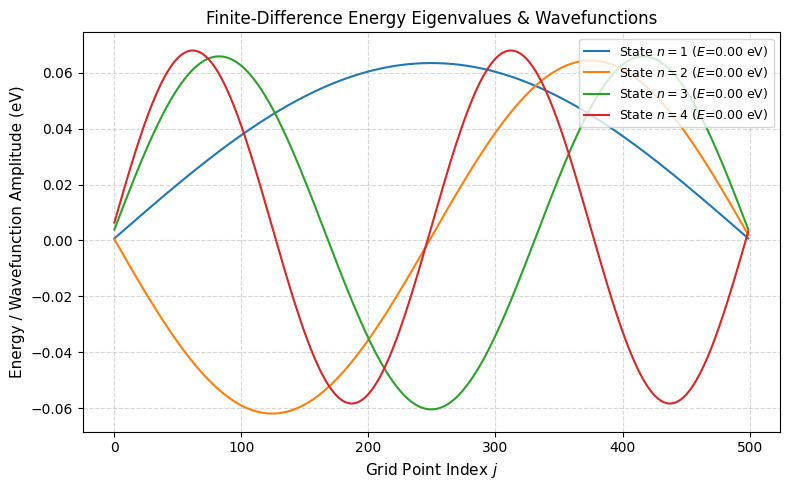

In [7]:
N = 500  # Number of grid points
a = 1.0  # Grid spacing in Å
hbar_sq_over_2m0 = 3.810  # eV·Å^2
m_target = 0.5  # Target effective mass in units of m0

# Finite difference prefactor (t_eff = ħ^2 / (2 * m* * a^2))
t_eff = hbar_sq_over_2m0 / (m_target * a**2)

# Correctly construct 1-D arrays for diagonal and off-diagonal elements
diag = 2 * t_eff * np.ones(N)
off_diag = -t_eff * np.ones(N - 1)

# Build the real-space finite-difference matrix
H = np.diag(diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)

num_levels = 10

energies, wavefunctions = eigh(H, subset_by_index=[0, num_levels - 1])

print(f'--- FIRST {num_levels} ENERGY LEVELS ---')
for i, E in enumerate(energies):
  print(f'E_{i+1} = {E:.4f} eV')
plt.figure(figsize=(8, 5))
for i in range(min(4, num_levels)):
  plt.plot(
      wavefunctions[:, i] + energies[i], label=f'State $n={i+1}$ ($E$={energies[i]:.2f} eV)'
  )

plt.xlabel('Grid Point Index $j$', fontsize=11)
plt.ylabel('Energy / Wavefunction Amplitude (eV)', fontsize=11)
plt.title('Finite-Difference Energy Eigenvalues & Wavefunctions', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

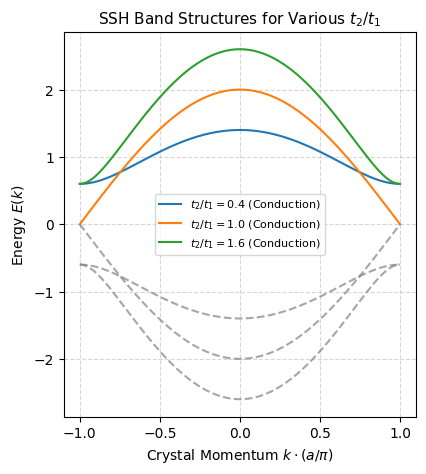

In [10]:
a = 1.0
t1 = 1.0
t2 = [0.4, 1.0, 1.6]  # Different t2/t1 ratios
N_k = 300
k_grid = np.linspace(-np.pi / a, np.pi / a, N_k)

plt.figure(figsize=(10,5))

for i,t2 in enumerate(t2):
    ratios = t2/ t1
    E_minus = np.zeros(N_k)
    E_plus = np.zeros(N_k)

    for j ,k in enumerate(k_grid):
        off_diag = t1 +t2*np.exp(-1j*k*a)
        H_k = np.array([[0,off_diag],[np.conj(off_diag),0]])

        evals,_ = np.linalg.eigh(H_k)
        
        E_minus[j]=evals[0]
        E_plus[j]=evals[1]

        
    plt.subplot(1, 2, 1)
    plt.plot(
      k_grid * a / np.pi, E_plus, label=f'$t_2/t_1 = {t2}$ (Conduction)' )
    plt.plot(
      k_grid * a / np.pi, E_minus, linestyle='--', color='gray', alpha=0.7)

plt.subplot(1, 2, 1)
plt.title('SSH Band Structures for Various $t_2/t_1$', fontsize=11)
plt.xlabel(r'Crystal Momentum $k \cdot (a / \pi)$', fontsize=10)
plt.ylabel('Energy $E(k)$', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=8)

<>:8: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:8: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_30144\3949358259.py:8: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  plt.ylabel('Band Gap $\Delta$', fontsize=10)


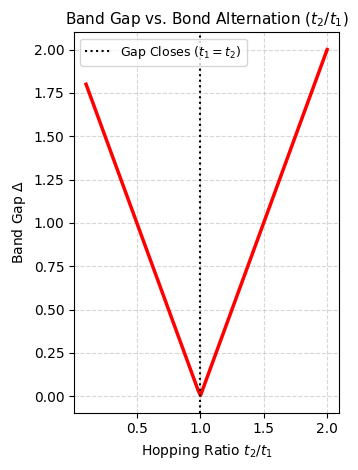

In [14]:
t2_range = np.linspace(0.1, 2.0, 100) # took for values of t2 of a different range 
band_gaps = 2 * np.abs(t1 - t2_range)

plt.subplot(1, 2, 2)
plt.plot(t2_range / t1, band_gaps, 'r-', linewidth=2.5)
plt.title('Band Gap vs. Bond Alternation ($t_2 / t_1$)', fontsize=11)
plt.xlabel(r'Hopping Ratio $t_2 / t_1$', fontsize=10)
plt.ylabel('Band Gap $\Delta$', fontsize=10)
plt.axvline(1.0, color='black', linestyle=':', label='Gap Closes ($t_1 = t_2$)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=9)

plt.tight_layout()
plt.show()

<>:26: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:26: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_30144\3351883237.py:26: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  plt.ylabel('Band Gap $\Delta$', fontsize=10)


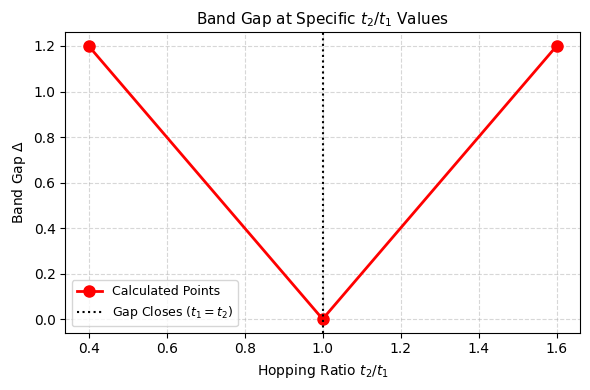

In [12]:
# Parameters (took for values of t2 given to us)
t1 = 1.0
t2_values = [0.4, 1.0, 1.6]

# Calculate band gaps for your discrete list
# For the SSH model, the band gap is analytically given by Delta = 2 * abs(t1 - t2)
band_gaps = [2 * abs(t1 - t2) for t2 in t2_values]
ratios = [t2 / t1 for t2 in t2_values]

# Plotting discrete points
plt.figure(figsize=(6, 4))
plt.plot(
    ratios,
    band_gaps,
    'ro-',
    linewidth=2,
    markersize=8,
    label='Calculated Points',
)

plt.title('Band Gap at Specific $t_2 / t_1$ Values', fontsize=11)
plt.xlabel(r'Hopping Ratio $t_2 / t_1$', fontsize=10)
plt.ylabel('Band Gap $\Delta$', fontsize=10)
plt.axvline(1.0, color='black', linestyle=':', label='Gap Closes ($t_1 = t_2$)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [19]:
## task 3 ##
hbar=1
a=0.5
m=1
P = [0.1,1,5,20]
q_vals = np.linspace(0.01, 25.0, 4000)
for idx,p in enumerate(P):
    reduced_k = []
    reduced_E = []
    extended_k = []
    extended_E = []
    for q in q_vals:
        val = np.cos(q*a)+ ( p/ (q*a) ) * np.sin(q*a)  # cos(ka)

        if -1<=  val <= 1:
            k = np.arccos(val)/a
            E = hbar * q**2 / (2*m)

            # Reduced zone scheme (-pi/a to pi/a)
            for sign in [-1, 1]:
                reduced_k.append(sign * k)
                reduced_E.append(E)

           # Extended zone scheme (-3pi/a to 3pi/a)
            for n in [-2, -1, 0, 1, 2]:
                extended_k.append(sign * k + n * (2 * np.pi / a))
                extended_E.append(E)
    

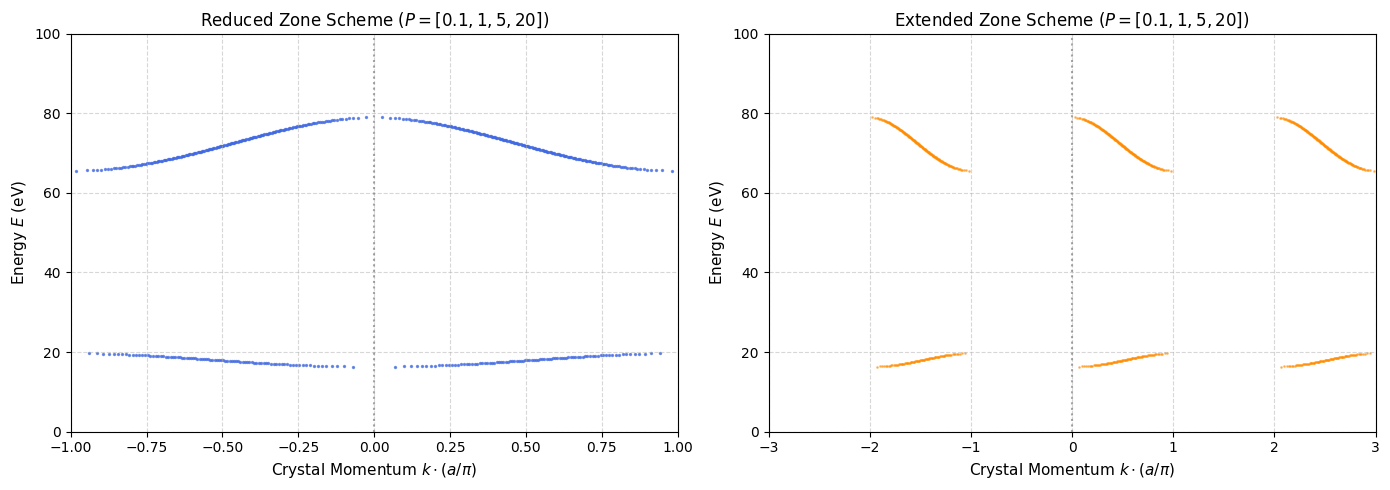

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# 1. Reduced Zone Scheme
axes[0].scatter(
    np.array(reduced_k) * a / np.pi,
    reduced_E,
    s=2,
    color='royalblue',
    alpha=0.7,
)
axes[0].set_title(f'Reduced Zone Scheme ($P = {P}$)', fontsize=12)
axes[0].set_xlabel(r'Crystal Momentum $k \cdot (a / \pi)$', fontsize=11)
axes[0].set_ylabel('Energy $E$ (eV)', fontsize=11)
axes[0].set_xlim(-1, 1)
axes[0].set_ylim(0, 100)
axes[0].axvline(0, color='gray', linestyle=':', alpha=0.7)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Extended Zone Scheme
axes[1].scatter(
    np.array(extended_k) * a / np.pi,
    extended_E,
    s=1,
    color='darkorange',
    alpha=0.5,
)
axes[1].set_title(f'Extended Zone Scheme ($P = {P}$)', fontsize=12)
axes[1].set_xlabel(r'Crystal Momentum $k \cdot (a / \pi)$', fontsize=11)
axes[1].set_ylabel('Energy $E$ (eV)', fontsize=11)
axes[1].set_xlim(-3, 3)
axes[1].set_ylim(0, 100)
axes[1].axvline(0, color='gray', linestyle=':', alpha=0.7)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [44]:
P_kp = 1.0
q_vals = np.linspace(0.01, 25.0, 4000)
kp_k, kp_E = [], []

for q in q_vals:
  rhs = np.cos(q * a) + (P_kp / (q * a)) * np.sin(q * a)
  if -1.0 <= rhs <= 1.0:
    k = np.arccos(rhs) / a
    E = (hbar**2) * (q**2) / (2 * m)
    for sign in [-1, 1]:
      kp_k.append(sign * k)
      kp_E.append(E)

In [45]:
N_cell = 100
dx = a / N_cell
t_fd = hbar**2 / (2 * m * dx**2)
V0_fd = 1.5  # Equivalent potential strength

x_cell = np.linspace(0, a, N_cell, endpoint=False)
V_x = 2 * V0_fd * np.cos(2 * np.pi * x_cell / a)

fd_energies = []
for k in k_grid:
  H = np.zeros((N_cell, N_cell), dtype=complex)
  for i in range(N_cell):
    H[i, i] = 2 * t_fd + V_x[i]
    if i < N_cell - 1:
      H[i, i + 1] = -t_fd
      H[i + 1, i] = -t_fd
    else:
      H[i, 0] = -t_fd * np.exp(1j * k * a)
      H[0, i] = -t_fd * np.exp(-1j * k * a)
  evals, _ = np.linalg.eigh(H)
  fd_energies.append(evals)
fd_energies = np.array(fd_energies)

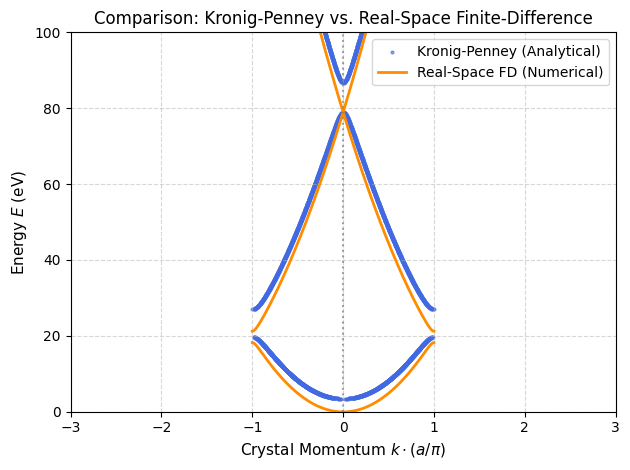

In [46]:
# Plot Real-Space Finite-Difference (Lines)

plt.scatter(
    np.array(kp_k) * a / np.pi,
    kp_E,
    s=4,
    color='royalblue',
    alpha=0.6,
    label='Kronig-Penney (Analytical)',
)
for band in range(min(3, N_cell)):
  label_str = (
      'Real-Space FD (Numerical)' if band == 0 else ''
  )  # Label only once
  plt.plot(
      k_grid * a / np.pi,
      fd_energies[:, band],
      color='darkorange',
      linestyle='-',
      linewidth=2,
      label=label_str,
  )
    
plt.title(
    'Comparison: Kronig-Penney vs. Real-Space Finite-Difference', fontsize=12
)
plt.xlabel(r'Crystal Momentum $k \cdot (a / \pi)$', fontsize=11)
plt.ylabel('Energy $E$ (eV)', fontsize=11)
plt.xlim(-3, 3)
plt.ylim(0, 100)
plt.axvline(0, color='gray', linestyle=':', alpha=0.7)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()